# MuSGD × YOLO26: measured development review

This companion contains an immutable snapshot of downloaded Kaggle measurements and runnable analysis code. It runs on CPU, uses no torch, and performs no training or test-set evaluation. The training notebooks are separate artifacts.

**Status:** engineering development evidence, with provisional learning rates. No paper-level optimizer ranking or uncertainty claim follows from a one-seed run.

## 1. Restore and verify the measured snapshot
Input JSON and per-epoch CSV hashes identify the source artifacts. The complete reviewed snapshot is embedded so the saved notebook remains usable without Kaggle credentials.

In [1]:
import json, hashlib, math
from IPython.display import display, Markdown
DATA = json.loads('{"artifact_sha256": {"checkpoint_lineage.json": "e31e0601148997a3d40b21503fc117b5ad28a94697566a980897c7d985a08211", "manifest.json": "63735f7ed7377cc3ee60616d7bd39412b937e39c029f919533be2d6b30ab512e", "results.json": "88bafcc3b08f022faa1d80eb9d8d32a904a4f0616f96f300efa16eaa72cb8ad3", "runs/smoke-AdamW-s42-edef07d033b4/attempt-001/train/results.csv": "fa41d62caf4c8e0a013c14b3741048e522fdf1d3dd507e21ecd37ab38f752140", "runs/smoke-MuSGD-s42-83bf9f7cfdda/attempt-001/train/results.csv": "83724c39b3a9574b8a83bc8d3eb87788a1ffb3cd98f46510449c69a90f0dcbbb", "split_audit.json": "c6a488a4abe4e861808d666d75a7d650c864f810cef4ae3b8529c1777a76e443", "variant_audit.json": "7b4e31ec329d234656d6b644760e7c2d814fc8b01831ffc98a7984cb8326a55b"}, "checkpoint": {"checkpoint": "yolo26n.pt", "git": {"branch": "exp-main", "commit": "cb13d5f9cfbd6f299da3620c625f81d721dc2849", "origin": "https://github.com/ultralytics/ultralytics.git", "root": "/home/lq/codes/ultralytics"}, "note": "COCO category overlap and possible source-image overlap need discussion", "pretraining_train_args": {"agnostic_nms": false, "amp": true, "augment": false, "auto_augment": "randaugment", "batch": 128, "bgr": 0.10567, "box": 5.62767, "cache": false, "cfg": null, "classes": null, "close_mosaic": 10, "cls": 0.56099, "cls_w": 2.7371, "compile": false, "conf": null, "copy_paste": 0.07504, "copy_paste_mode": "flip", "cos_lr": false, "cutmix": 0.0, "data": "/home/lq/codes/ultralytics/ultralytics/cfg/datasets/coco.yaml", "degrees": 1.11032, "detach_epoch": 10, "deterministic": true, "device": "5", "dfl": 9.03871, "dnn": false, "dropout": 0.0, "dynamic": false, "embed": null, "end2end": true, "epochs": 245, "erasing": 0.4, "exist_ok": false, "fliplr": 0.60571, "flipud": 0.05854, "format": "torchscript", "fraction": 1.0, "freeze": null, "half": false, "hsv_h": 0.01373, "hsv_s": 0.64481, "hsv_v": 0.56565, "imgsz": 640, "int8": false, "iou": 0.7, "keras": false, "kobj": 1.0, "line_width": null, "lr0": 0.0054, "lrf": 0.04952, "mask_ratio": 4, "max_det": 300, "mixup": 0.01216, "mode": "train", "model": "yolo26n-objv1-150.pt", "momentum": 0.94676, "mosaic": 0.90863, "multi_scale": 0.0, "muon_w": 0.52782, "name": "train31", "nbs": 64, "nms": false, "o2m": 1.0, "opset": null, "optimize": false, "optimizer": "MuSGD", "overlap_mask": true, "patience": 100, "perspective": 0.00011, "plots": false, "pose": 12.0, "pretrained": true, "profile": false, "project": "tune-yolo26n-objv1-coco", "rect": false, "resume": false, "retina_masks": false, "save": true, "save_conf": false, "save_crop": false, "save_frames": false, "save_json": true, "save_period": -1, "save_txt": false, "scale": 0.56232, "seed": 0, "sgd_w": 0.6737, "shear": 1.46386, "show": false, "show_boxes": true, "show_conf": true, "show_labels": true, "simplify": true, "single_cls": false, "source": null, "split": "val", "stream_buffer": false, "stride_ratio": 1.0, "task": "detect", "time": null, "topk": 8, "tracker": "botsort.yaml", "translate": 0.07105, "val": true, "verbose": true, "vid_stride": 1, "visualize": false, "warmup_bias_lr": 0.08114, "warmup_epochs": 0.98124, "warmup_momentum": 0.6576, "weight_decay": 0.00064, "workers": 8, "workspace": null}, "sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "source": "Official Ultralytics pretrained asset; recipe uses MuSGD"}, "class_names": {"0": "buffalo", "1": "elephant", "2": "rhino", "3": "zebra"}, "evidence_directory": "outputs\\\\kaggle_smoke_v4\\\\muon_yolo_smoke", "exclusions": [{"image_sha256": "161a6e1c9347e95963a9daff3cda2d32be9b0f38583b615e071eb08bae042f7c", "label_sha256": "c83f6f88c5797f99cd8be9767cad458aa79d8a63cce7aa8b0f001c4d1a640c95", "name": "3 (269).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "val"}, {"image_sha256": "161a6e1c9347e95963a9daff3cda2d32be9b0f38583b615e071eb08bae042f7c", "label_sha256": "1a881e5e90ad98bace86f8d5e6698d731d55845f1750a0b036a6dee334f7a076", "name": "3 (318).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "val"}, {"image_sha256": "41df39bfc658a2251bf042ea3a8b8eda1b68d136cc9426c35b6e571b7655b572", "label_sha256": "694f0eac991a278638d5734034384db9c40625a2611bd2e93a547025bf0394c1", "name": "1 (124).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "8b746c4a4f1d72e57786ba6cd010e8108d24b9d455e7a14fe759bed8a92ab250", "label_sha256": "acf31e2e0848ee2d4ae5cfab57606d1266f22fd3a56fdd18ae3ec257559cb5eb", "name": "1 (151).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "ed65685d547dab40061f58dc46f0e8741c55b4905776ee837fc21c9f6ea25423", "label_sha256": "ac222df22db3f61cdda086475d4f8a9a3f1ea6c8a94ebabe5eb4518eb8d90a8e", "name": "1 (229).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "64c330c35f2495d27e4fe48ef7589f4b9190ab84bf8034b97eff9fba73ae3f44", "label_sha256": "a3c9abb4c2ec490fa81f8e207c8338a041ffd16eaf32fb4f496767cc68aca27d", "name": "1 (322).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "5dffcefaba07261a23914d706d4b392c6649a70eee6fd9d3c68a6a01a9d6deef", "label_sha256": "460582cdbb6bc34f3bb357a6cf7a9a4065d2749d00924f94ea625dc84b60d190", "name": "1 (371).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "424163fcf8e6665d874bf6bb09d63678753490be2cbf4d4c0dec765c22669306", "label_sha256": "1be2c69a6708f3ef68132df0bb12042a8195abe3d43eb93a575e5f85c074dc4f", "name": "1 (98).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "c04b86583b08f6d3faaab9105947c30442b2cefd1a80fa1d64b3f612a6fcc040", "label_sha256": "443c20db62231761c5e7b2d00e9167f94d3f8010715f38ec4d58a5da47b987ad", "name": "2 (237).jpg", "objects": 4, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "1556ec22072b0d13d2dfde1d740c3213394dcff69d7ec89f30b27568feaf77dd", "label_sha256": "878acec88d65853ba3d1d32740e1ce38dbbdfd36abdf74349f2c49146c3b11d2", "name": "2 (242).jpg", "objects": 2, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "a2fa3e6766cdf9bc5ebac5bc3885ae12bb216ab757307dc5fb88bc7fa2050848", "label_sha256": "5c0a8aee716ef0ee9d8d257361f2a0ec3e9d23ac4c9edbcaac5b06113a9c43e4", "name": "2 (373).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "ca2e6934e437b493618ba6d024e27783e45c6f772d32d4d74c1119e5dde5bf7c", "label_sha256": "c845377bed1be358fe52c63ff281c0d02139f476d0838b1ab2bd750a8ff1720b", "name": "3 (230).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "5049dde9d116e5f742a433f5e5c48714f00fd29e79744eb2719bcc4b85956b37", "label_sha256": "d4ecd3107b0e42076bfffce027658a6353ce29da9538f6ad700e9df3a8a4bcef", "name": "3 (235).jpg", "objects": 2, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "4412536800ded33301e82e9242fb224ab689de02469962bb993184014889cb67", "label_sha256": "bcff4a37157f4bd1d10ce223a4f3a186cca89c393b2f261e222961b9164cbc54", "name": "3 (321).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "89bb2c078800d43e9db98adfb6c703b51485180809af3f7bce8a492ebd7082b0", "label_sha256": "1b0d846d9547ca60f7f7fd2a8c7535ff68175a6fce768ea10efb8864a4cf6d00", "name": "3 (342).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "4b6f50daf119ef57f7c7549d8482523c5603f71b02763119134e2698a9db0faf", "label_sha256": "d5e43a35529067b18b5961035f6e1c1e7e7cd404624eaead5438051f45623d0b", "name": "3 (360).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "475f293f5e81956e3730a5e6c0f88129f50540285e95b0d78d8c35dd19404714", "label_sha256": "1cf26c71b9bbed6dd17c3c20ffbdbe76c0f43eac9d674edfa439f1061493498a", "name": "4 (236).jpg", "objects": 3, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "e364f55729b5a8272f4c0a39b08aa1c67f0ad2d1fc3333e53e0480ec3ab28639", "label_sha256": "c2ac1cbb3665d11dfda32da23b4c07002d7cf33dbe7de92bd781729ab52854f3", "name": "4 (253).jpg", "objects": 3, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "dd4b54a043e27c77fefb0d5dbb716ab65c402abb4c42d489b90c2d4b966bf397", "label_sha256": "e8347335106911fbde6f6cad506132a6e84c27baf8371fd6572db233d4cab259", "name": "4 (320).jpg", "objects": 3, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "c3ab57677ae479979362b1150df30a8d1a8e3ac994686b873934882f074e88e4", "label_sha256": "9f638cfd08d52ee912d3969dda01168cbe78b747c1e9bf082c7d3e7e808b4d17", "name": "4 (342).jpg", "objects": 1, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "f589f0b3e2fba5dd3604bf0bdc22bbba24a37d72323aaba687e8e93c5d05cd9f", "label_sha256": "3e157f5a34499dc84d7eb5d8e26e453ca0ce339737182dafecb2bf5bca73fb01", "name": "4 (364).jpg", "objects": 2, "reason": "exact image also in higher-priority held-out split", "split": "train"}, {"image_sha256": "333a2bdf0151975f9e90e0d628318e85a119bdd9fabe021953df8d1c737b6232", "label_sha256": "2897031b279720f8e270d2823af738ed04f2dfe6970c2355a88848b45fa7fc6c", "name": "1 (314).jpg", "objects": 2, "peer_name": "1 (183).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "475a41cb825a28f1b6e5860c0cd36bf3ccdfa21546068fecd48da697ec84ff9b", "label_sha256": "bfdbb3bbc5adf28661ad13d2d0638ac0c5b81529a9a80c2a0b369b711a25a19a", "name": "1 (315).jpg", "objects": 1, "peer_name": "1 (356).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "4ff8ae1bef05fc876ee58f22805e1c3330bc17904ba3dad94b673b515e21f138", "label_sha256": "3cc671fb91182a0a4fe6556b53dbac54daad14d5846c5a9155a38a57d6047616", "name": "1 (355).jpg", "objects": 3, "peer_name": "1 (192).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "a8bfa1ccac93f1486a8eda10fb6010e3ed1045e42b29394f819909d6bdc75762", "label_sha256": "f3741ff6bc3571ce03ce940e23ec682f1582aa3584bb687666001e25b5cc57c9", "name": "1 (360).jpg", "objects": 1, "peer_name": "1 (334).jpg", "peer_split": "val", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "a3df8dceed0531f3600842c4bb1431ef7eece0e283ffb517ea5e8bcb9a273dc8", "label_sha256": "413ef63c03df4ef8612f892a7633b1b50bf9f3f5b7dd4a9728e819990e458e34", "name": "1 (86).jpg", "objects": 1, "peer_name": "1 (128).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "3a327307de3e6c7a1b11eb89ae5d702781a6055e23ccaab0aa7dba520d734fed", "label_sha256": "647f2ae0e9338e55a3c2fad03899c810adb3670b43e50682a5110c337cbf53aa", "name": "3 (116).jpg", "objects": 2, "peer_name": "3 (323).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "6797722d2e48ec38de079ed14f0e535c8d5dadd8c4a9e8dd113036fc3bf504b0", "label_sha256": "8e1a456069b51c4d31eb8f3a71a01ceef817acfaea8e7f080a28b521671efadc", "name": "3 (275).jpg", "objects": 2, "peer_name": "3 (192).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "e3d561933cedac6452293507a8d19ff820a5039a1fa89f4d696ff086f3d77738", "label_sha256": "44b78776dfa23536078261b0647316d97afdb07552cad832264172e514cb5832", "name": "1 (237).jpg", "objects": 1, "peer_name": "1 (365).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "ec8e84546f43dd8bf28dcc13776156b141367b5d24bfa85ef49900e43b86b521", "label_sha256": "2844581d7b776e6a52a97fae7a95e0fe84606564e649900a71728cfb35227a11", "name": "1 (70).jpg", "objects": 3, "peer_name": "1 (74).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "ab272b4483a06923c42f5f5cdbe84311499f4374ba630b9f02d5a71d199dd49a", "label_sha256": "74fd5b0ff4be7e06f39528c62312a79d3538ea6e8ac060239ce33b8e6d06d079", "name": "3 (311).jpg", "objects": 1, "peer_name": "3 (364).jpg", "peer_split": "val", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "f4dc90fdc67756381dfd1b19a7595d6d2d0e6cf0425719254c498a83f477bbf7", "label_sha256": "2901db8a9ee8be1fb1c840ef7526489e65085b660877f94f6cde19b7a1347432", "name": "1 (325).jpg", "objects": 1, "peer_name": "1 (55).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}, {"image_sha256": "6ce0676e0dc81394f8fa0355f5ccb06a3a05423540bfb6bd868a261fbb8e2046", "label_sha256": "d39a87b0a17022869a0bdc6486c5f445af75d2694cebd220f94c1958ff205d4b", "name": "1 (175).jpg", "objects": 1, "peer_name": "1 (356).jpg", "peer_split": "test", "reason": "visually reviewed cross-split near duplicate", "split": "train"}], "histories": {"smoke-AdamW-s42-edef07d033b4": [{"epoch": 1.0, "lr/pg0": 0.001, "lr/pg1": 0.001, "lr/pg2": 0.001, "metrics/mAP50(B)": 0.08162, "metrics/mAP50-95(B)": 0.03224, "metrics/precision(B)": 0.07355, "metrics/recall(B)": 0.3901, "time": 26.1351, "train/box_loss": 1.35438, "train/cls_loss": 5.30256, "train/l1_loss": 0.02856, "val/box_loss": 1.54347, "val/cls_loss": 3.98512, "val/l1_loss": 0.03714}, {"epoch": 2.0, "lr/pg0": 0.000505, "lr/pg1": 0.000505, "lr/pg2": 0.000505, "metrics/mAP50(B)": 0.03761, "metrics/mAP50-95(B)": 0.01342, "metrics/precision(B)": 0.03941, "metrics/recall(B)": 0.23214, "time": 30.0373, "train/box_loss": 1.34588, "train/cls_loss": 4.36725, "train/l1_loss": 0.02375, "val/box_loss": 1.64683, "val/cls_loss": 3.84003, "val/l1_loss": 0.04068}], "smoke-MuSGD-s42-83bf9f7cfdda": [{"epoch": 1.0, "lr/pg0": 0.03, "lr/pg1": 0.01, "lr/pg2": 0.03, "lr/pg3": 0.01, "lr/pg4": 0.03, "lr/pg5": 0.01, "lr/pg6": 0.03, "lr/pg7": 0.01, "metrics/mAP50(B)": 0.24474, "metrics/mAP50-95(B)": 0.12603, "metrics/precision(B)": 0.513, "metrics/recall(B)": 0.3361, "time": 2.8452, "train/box_loss": 1.11924, "train/cls_loss": 4.52771, "train/l1_loss": 0.02249, "val/box_loss": 1.26976, "val/cls_loss": 3.62008, "val/l1_loss": 0.02933}, {"epoch": 2.0, "lr/pg0": 0.01515, "lr/pg1": 0.00505, "lr/pg2": 0.01515, "lr/pg3": 0.00505, "lr/pg4": 0.01515, "lr/pg5": 0.00505, "lr/pg6": 0.01515, "lr/pg7": 0.00505, "metrics/mAP50(B)": 0.23019, "metrics/mAP50-95(B)": 0.12344, "metrics/precision(B)": 0.52614, "metrics/recall(B)": 0.25833, "time": 5.22109, "train/box_loss": 1.15613, "train/cls_loss": 3.23313, "train/l1_loss": 0.01931, "val/box_loss": 1.49231, "val/cls_loss": 3.02095, "val/l1_loss": 0.03588}]}, "manifest": {"completed_runs": 2, "environment": {"cuda": "12.8", "cudnn": 91900, "device_used": 0, "gpu": "Tesla T4", "gpu_count_visible": 2, "gpu_total_bytes": 15636037632, "musgd_source_sha256": "b2781aaf53a5e1796ae0ec628c5c15b39b1658cc3deba67d4a8a5aae5ed05a4d", "platform": "Linux-6.18.55+-x86_64-with-glibc2.39", "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]", "torch": "2.11.0+cu128", "trainer_source_sha256": "7d060019b31e85ec429c16b7e728e9d7c5a9083b497fc2b362a76a543808dc60", "ultralytics": "8.4.187"}, "experiment_identity": {"checkpoint_sha256": "9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef", "environment": {"cuda": "12.8", "cudnn": 91900, "device_used": 0, "gpu": "Tesla T4", "gpu_count_visible": 2, "gpu_total_bytes": 15636037632, "musgd_source_sha256": "b2781aaf53a5e1796ae0ec628c5c15b39b1658cc3deba67d4a8a5aae5ed05a4d", "platform": "Linux-6.18.55+-x86_64-with-glibc2.39", "python": "3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]", "torch": "2.11.0+cu128", "trainer_source_sha256": "7d060019b31e85ec429c16b7e728e9d7c5a9083b497fc2b362a76a543808dc60", "ultralytics": "8.4.187"}, "source_fingerprint": "b3114f1579a97b5443fe1877fc5b1a293f4f947b86ff0ed0f364a7f1bd037137"}, "identity": {"code_sha256": "ee66b4fe84329babe32713f88080320354ac906fff2a39d1ea50e607e3ea7466", "config": {"checkpoint": "yolo26n.pt", "corruption_seed": 2027, "dataset": "african-wildlife.yaml", "evaluation": {"augment": false, "conf": 0.001, "half": false, "iou": 0.7, "max_det": 300, "split": "val"}, "fractions": [0.05], "noise_levels": [0.2], "noise_type": "missing_box", "optimizers": {"AdamW": {"lr0": 0.001, "momentum": 0.9, "weight_decay": 0.0005}, "MuSGD": {"lr0": 0.01, "momentum": 0.9, "weight_decay": 0.0005}}, "reviewed_exclusions_file": "duplicate_exclusions.json", "split_policy": "holdout_priority_reviewed_v2", "study": "smoke", "subset_seed": 2026, "train": {"amp": false, "batch": 8, "cache": false, "close_mosaic": 0, "cls_remap": false, "compile": false, "copy_paste": 0.0, "cos_lr": false, "cutmix": 0.0, "degrees": 0.0, "deterministic": true, "device": 0, "epochs": 2, "fliplr": 0.5, "flipud": 0.0, "hsv_h": 0.015, "hsv_s": 0.7, "hsv_v": 0.4, "imgsz": 320, "lrf": 0.01, "mixup": 0.0, "mosaic": 0.0, "multi_scale": 0.0, "nbs": 8, "patience": 0, "perspective": 0.0, "plots": false, "rect": false, "save": true, "scale": 0.5, "shear": 0.0, "translate": 0.1, "val": true, "warmup_bias_lr": 0.0, "warmup_epochs": 0.0, "warmup_momentum": 0.8, "workers": 2}, "training_seeds": [42], "ultralytics_version": "8.4.187"}}, "planned_runs": 2, "purpose": "Pipeline smoke/pilot; learning rates are provisional and untuned", "status": "completed", "test_evaluated": false, "updated_utc": "2026-10-24T21:14:40.702803+00:00"}, "rows": [{"actual_train_images": 52, "attempt": 1, "best_validation_epoch": 1, "best_validation_map50_95": 0.03224, "best_weights": "/kaggle/working/muon_yolo_smoke/runs/smoke-AdamW-s42-edef07d033b4/attempt-001/train/weights/best.pt", "best_weights_sha256": "889deed56015d6a60d4dfa7b4b1a241705f744c86bb16ffdc98dccb66d5ce79b", "data_fraction": 0.05, "epochs_budget": 2, "epochs_completed": 2, "finished_utc": "2026-10-24T21:14:29.544183+00:00", "images_seen": 104, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "lr0": 0.001, "noise_probability": 0.2, "optimizer": "AdamW", "optimizer_details": {"class": "AdamW", "groups": [{"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "weight", "parameters": 2515728, "weight_decay": 0.0005}, {"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "bn", "parameters": 9784, "weight_decay": 0.0}, {"amsgrad": false, "betas": [0.9, 0.999], "capturable": false, "decoupled_weight_decay": true, "differentiable": false, "eps": 1e-08, "foreach": null, "fused": true, "initial_lr": 0.001, "lr": 0.001, "maximize": false, "param_group": "bias", "parameters": 9832, "weight_decay": 0.0}], "muon_factor": null, "sgd_factor": null}, "optimizer_steps": 14, "realized_noise_rate": 0.19387755102040816, "run_id": "smoke-AdamW-s42-edef07d033b4", "seed": 42, "spec_sha256": "edef07d033b4d30ff9dccced508585e73b1c49fca5e9f731ac041b2496e75723", "started_utc": "2026-10-24T21:13:35.757444+00:00", "status": "completed", "test_evaluated": false, "train_images": 52, "training_peak_vram_bytes": 652165120, "training_seconds": 51.32363456100006, "val_map50": 0.08080655891900528, "val_map50_95": 0.03233814735413029, "val_per_class_map50_95": [0.030466311317905736, 0.03817252018972924, 0.024021851400149518, 0.03669190650873667], "val_precision": 0.07193430880570621, "val_recall": 0.39585632448627894, "variant_fingerprint": "802247c431a5c1aa9d491bfd5381001dad03ed563ec14b4e55a82c99c314b07a"}, {"actual_train_images": 52, "attempt": 1, "best_validation_epoch": 1, "best_validation_map50_95": 0.12603, "best_weights": "/kaggle/working/muon_yolo_smoke/runs/smoke-MuSGD-s42-83bf9f7cfdda/attempt-001/train/weights/best.pt", "best_weights_sha256": "06750466a77b703e0cd12ec0730e0934768634bb0f87fa8c8fa436e23015786b", "data_fraction": 0.05, "epochs_budget": 2, "epochs_completed": 2, "finished_utc": "2026-10-24T21:14:39.910831+00:00", "images_seen": 104, "initial_model_state_sha256": "111da1631eb4bf77119eb03027af923422e35187cf064187db2f22fe8f0409e6", "lr0": 0.01, "noise_probability": 0.2, "optimizer": "MuSGD", "optimizer_details": {"class": "MuSGD", "groups": [{"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "weight", "parameters": 0, "use_muon": false, "weight_decay": 0.0005}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "weight", "parameters": 0, "use_muon": false, "weight_decay": 0.0005}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bn", "parameters": 2336, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bn", "parameters": 7448, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "bias", "parameters": 2360, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "bias", "parameters": 7472, "use_muon": false, "weight_decay": 0.0}, {"initial_lr": 0.03, "lr": 0.03, "momentum": 0.9, "nesterov": true, "param_group": "muon", "parameters": 124384, "use_muon": true, "weight_decay": 0.0005}, {"initial_lr": 0.01, "lr": 0.01, "momentum": 0.9, "nesterov": true, "param_group": "muon", "parameters": 2391344, "use_muon": true, "weight_decay": 0.0005}], "muon_factor": 0.2, "sgd_factor": 1.0}, "optimizer_steps": 14, "realized_noise_rate": 0.19387755102040816, "run_id": "smoke-MuSGD-s42-83bf9f7cfdda", "seed": 42, "spec_sha256": "83bf9f7cfdda7ac1c76a54deef8feabe59c5417e405a0af984e1d797c926be75", "started_utc": "2026-10-24T21:14:29.911518+00:00", "status": "completed", "test_evaluated": false, "train_images": 52, "training_peak_vram_bytes": 694936064, "training_seconds": 8.298483823999959, "val_map50": 0.23875665647130478, "val_map50_95": 0.12486307474186562, "val_per_class_map50_95": [0.03800259615650893, 0.08866265711216273, 0.12164777498897125, 0.2511392707098197], "val_precision": 0.5227079281851207, "val_recall": 0.3246367083882472, "variant_fingerprint": "802247c431a5c1aa9d491bfd5381001dad03ed563ec14b4e55a82c99c314b07a"}], "source_fingerprint": "3d81e08098b499d73730d9f6293232f4d0b41abe4d5a2994320ce40238af9644", "split_counts": {"test": {"empty_labels": 0, "images": 227, "objects": 375}, "train": {"empty_labels": 0, "images": 1021, "objects": 1881}, "val": {"empty_labels": 0, "images": 223, "objects": 377}}, "split_fingerprint": "b3114f1579a97b5443fe1877fc5b1a293f4f947b86ff0ed0f364a7f1bd037137", "split_policy": "holdout_priority_reviewed_v2", "variants": [{"clean_val_and_test_byte_identical_to_frozen_splits": true, "config": {"corruption_seed": 2027, "fraction": 0.05, "noise": 0.2, "noise_type": "missing_box", "schema": 1, "source_fingerprint": "b3114f1579a97b5443fe1877fc5b1a293f4f947b86ff0ed0f364a7f1bd037137", "subset_seed": 2026}, "empty_train_labels": 7, "fingerprint": "802247c431a5c1aa9d491bfd5381001dad03ed563ec14b4e55a82c99c314b07a", "original_train_objects": 98, "realized_noise_rate": 0.19387755102040816, "remaining_train_objects": 79, "removed_objects": 19, "train_images": 52, "variant_id": "a238b0a428a32889"}]}')
assert hashlib.sha256(json.dumps(DATA, sort_keys=True).encode()).hexdigest() == 'c9fd5017b632f465870029a8956c42daf5c4cf98ccb4384dde53edb201ed3d02'
rows = DATA['rows']
completed = [r for r in rows if r['status'] == 'completed']
assert all(not r['test_evaluated'] for r in rows)
assert all(math.isfinite(r['val_map50_95']) for r in completed)
print('Snapshot verified; input artifact hashes:', len(DATA['artifact_sha256']))


Snapshot verified; input artifact hashes: 7


## 2. Execution and data integrity

In [2]:
m = DATA['manifest']
env = m['environment']
counts = DATA['split_counts']
display(Markdown(f"Completed **{len(completed)}/{m['planned_runs']}** planned runs. Manifest: **{m['status']}**. Test scored: **no**."))
display(Markdown(f"Hardware: {env['gpu']} device {env['device_used']}; torch {env['torch']}; Ultralytics {env['ultralytics']}."))
display(Markdown(f"Frozen image counts: **{counts['train']['images']} train / {counts['val']['images']} validation / {counts['test']['images']} test**. Policy: `{DATA['split_policy']}`; {len(DATA['exclusions'])} exclusions."))
display(Markdown('All retained labels are unchanged. Test membership is preserved; validation/training membership differs from the raw official splits. Near-duplicate review is not exhaustive.'))


Completed **2/2** planned runs. Manifest: **completed**. Test scored: **no**.

Hardware: Tesla T4 device 0; torch 2.11.0+cu128; Ultralytics 8.4.187.

Frozen image counts: **1021 train / 223 validation / 227 test**. Policy: `holdout_priority_reviewed_v2`; 33 exclusions.

All retained labels are unchanged. Test membership is preserved; validation/training membership differs from the raw official splits. Near-duplicate review is not exhaustive.

## 3. Validation measurements
mAP values below use the 0–1 scale. Runtime is the complete training call, including setup and validation; it is not a matched-time comparison. Peak allocated VRAM measures training allocations, not total GPU usage.

In [3]:
table = ['| Fraction | Missing-box probability | Optimizer | Seed | Val mAP50–95 | Epochs | Steps | Wall seconds |', '|---:|---:|---|---:|---:|---:|---:|---:|']
for r in sorted(completed, key=lambda r:(r['data_fraction'],r['noise_probability'],r['optimizer'],r['seed'])):
    table.append(f"| {r['data_fraction']:.0%} | {r['noise_probability']:.0%} | {r['optimizer']} | {r['seed']} | {r['val_map50_95']:.5f} | {r['epochs_completed']} | {r['optimizer_steps']} | {r['training_seconds']:.2f} |")
display(Markdown('\n'.join(table)))


| Fraction | Missing-box probability | Optimizer | Seed | Val mAP50–95 | Epochs | Steps | Wall seconds |
|---:|---:|---|---:|---:|---:|---:|---:|
| 5% | 20% | AdamW | 42 | 0.03234 | 2 | 14 | 51.32 |
| 5% | 20% | MuSGD | 42 | 0.12486 | 2 | 14 | 8.30 |

## 4. Paired differences
Pairing requires matching data fingerprints, initialized parameters, image exposure, steps and epochs. Differences are descriptive; repeated seeds and fair validation tuning are still required.

In [4]:
pairs=[]
for a in completed:
    if a['optimizer'] != 'AdamW': continue
    b=next((r for r in completed if r['optimizer']=='MuSGD' and r['seed']==a['seed'] and r['variant_fingerprint']==a['variant_fingerprint']),None)
    if b is None: continue
    for k in ['initial_model_state_sha256','images_seen','optimizer_steps','epochs_completed']:
        assert a[k]==b[k],k
    pairs.append((a['data_fraction'],a['noise_probability'],a['seed'],100*(b['val_map50_95']-a['val_map50_95'])))
display(Markdown('\n'.join(['| Fraction | Missing boxes | Seed | MuSGD − AdamW (AP points) |','|---:|---:|---:|---:|']+[f'| {f:.0%} | {n:.0%} | {s} | {d:+.3f} |' for f,n,s,d in pairs])))
print('Verified pairs:',len(pairs),'; training seeds:',len({r['seed'] for r in completed}))


| Fraction | Missing boxes | Seed | MuSGD − AdamW (AP points) |
|---:|---:|---:|---:|
| 5% | 20% | 42 | +9.252 |

Verified pairs: 1 ; training seeds: 1


## 5. Validation trajectories
Per-epoch training-validation scores can differ slightly from independent validation of the saved best weights. All panels share an axis scale. Colors and line styles identify optimizers.

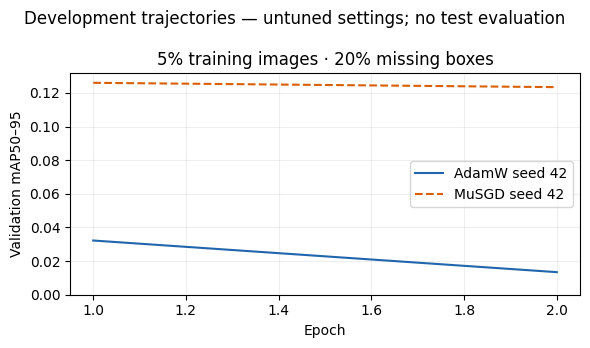

In [5]:
import matplotlib.pyplot as plt
conditions=sorted({(r['data_fraction'],r['noise_probability']) for r in completed})
cols=min(2,len(conditions)); height=3.5*math.ceil(len(conditions)/cols)
fig,axes=plt.subplots(math.ceil(len(conditions)/cols),cols,figsize=(6*cols,height),squeeze=False,sharey=True)
colors={'AdamW':'#2166ac','MuSGD':'#d95f02','SGD':'#1b9e77'}
styles={'AdamW':'-','MuSGD':'--','SGD':':'}
for ax,(fraction,noise) in zip(axes.flat,conditions):
    for r in completed:
        if (r['data_fraction'],r['noise_probability'])!=(fraction,noise):continue
        h=DATA['histories'][r['run_id']]
        ax.plot([e['epoch'] for e in h],[e['metrics/mAP50-95(B)'] for e in h],color=colors[r['optimizer']],linestyle=styles[r['optimizer']],label=f"{r['optimizer']} seed {r['seed']}")
    ax.set(title=f'{fraction:.0%} training images · {noise:.0%} missing boxes',xlabel='Epoch',ylabel='Validation mAP50–95')
    ax.set_ylim(bottom=0);ax.grid(alpha=0.2);ax.legend()
for ax in list(axes.flat)[len(conditions):]:ax.set_visible(False)
fig.suptitle('Development trajectories — untuned settings; no test evaluation')
fig.tight_layout();plt.show()


## 6. Corruption denominators and actual optimizer settings

In [6]:
for v in DATA['variants']:
    display(Markdown(f"Variant `{v['variant_id']}`: **{v['train_images']}** images; **{v['removed_objects']}/{v['original_train_objects']}** objects removed (**{v['realized_noise_rate']:.2%}**); **{v['empty_train_labels']}** empty training label files."))
group_table=['| Optimizer | Group | Parameters | Initial LR | Muon enabled |','|---|---|---:|---:|---|']
seen=set()
for r in completed:
    if r['optimizer'] in seen:continue
    seen.add(r['optimizer'])
    for g in r['optimizer_details']['groups']:
        if not g['parameters']:continue
        group_table.append(f"| {r['optimizer']} | {g.get('param_group','')} | {g['parameters']} | {g.get('initial_lr',g['lr']):.5f} | {g.get('use_muon',False)} |")
display(Markdown('\n'.join(group_table)))


Variant `a238b0a428a32889`: **52** images; **19/98** objects removed (**19.39%**); **7** empty training label files.

| Optimizer | Group | Parameters | Initial LR | Muon enabled |
|---|---|---:|---:|---|
| AdamW | weight | 2515728 | 0.00100 | False |
| AdamW | bn | 9784 | 0.00100 | False |
| AdamW | bias | 9832 | 0.00100 | False |
| MuSGD | bn | 2336 | 0.03000 | False |
| MuSGD | bn | 7448 | 0.01000 | False |
| MuSGD | bias | 2360 | 0.03000 | False |
| MuSGD | bias | 7472 | 0.01000 | False |
| MuSGD | muon | 124384 | 0.03000 | True |
| MuSGD | muon | 2391344 | 0.01000 | True |

## Class-specific validation AP
Each value is the saved best checkpoint's validation AP for that class, on the 0–1 scale.

In [7]:
names=[DATA['class_names'][str(i)] for i in range(len(DATA['class_names']))]
class_table=['| Fraction | Missing boxes | Optimizer | Seed | '+' | '.join(names)+' |', '|---:|---:|---|---:|'+'---:|'*len(names)]
for r in completed:
    values=r['val_per_class_map50_95']
    assert len(values)==len(names) and all(0<=v<=1 for v in values)
    prefix=f"| {r['data_fraction']:.0%} | {r['noise_probability']:.0%} | {r['optimizer']} | {r['seed']} | "
    class_table.append(prefix+' | '.join(f'{v:.4f}' for v in values)+' |')
display(Markdown('\n'.join(class_table)))


| Fraction | Missing boxes | Optimizer | Seed | buffalo | elephant | rhino | zebra |
|---:|---:|---|---:|---:|---:|---:|---:|
| 5% | 20% | AdamW | 42 | 0.0305 | 0.0382 | 0.0240 | 0.0367 |
| 5% | 20% | MuSGD | 42 | 0.0380 | 0.0887 | 0.1216 | 0.2511 |

## Training-loss diagnostics
Box and classification losses use separate panels/scales. Lower training loss alone does not establish generalization or explain an optimizer mechanism.

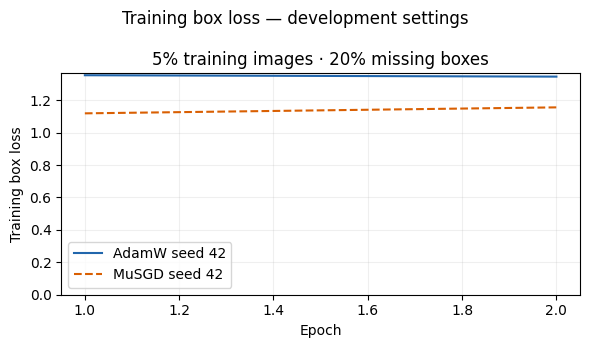

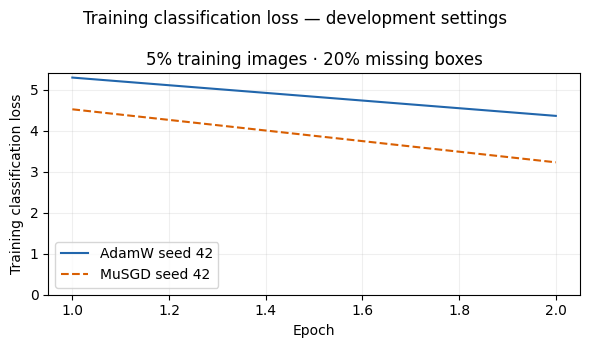

In [8]:
for field,ylabel in [('train/box_loss','Training box loss'),('train/cls_loss','Training classification loss')]:
    fig,axes=plt.subplots(math.ceil(len(conditions)/cols),cols,figsize=(6*cols,height),squeeze=False,sharey=True)
    for ax,(fraction,noise) in zip(axes.flat,conditions):
        for r in completed:
            if (r['data_fraction'],r['noise_probability'])!=(fraction,noise):continue
            h=DATA['histories'][r['run_id']]
            ax.plot([e['epoch'] for e in h],[e[field] for e in h],color=colors[r['optimizer']],linestyle=styles[r['optimizer']],label=f"{r['optimizer']} seed {r['seed']}")
        ax.set(title=f'{fraction:.0%} training images · {noise:.0%} missing boxes',xlabel='Epoch',ylabel=ylabel)
        ax.set_ylim(bottom=0);ax.grid(alpha=0.2);ax.legend()
    for ax in list(axes.flat)[len(conditions):]:ax.set_visible(False)
    fig.suptitle(ylabel+' — development settings')
    fig.tight_layout();plt.show()


## 7. What this evidence supports

Successful completion supports the experiment plumbing, deterministic variants and paired initialization checks. It does not establish a general optimizer advantage, a scarcity/noise interaction, a causal mechanism or significance. The implemented recipes differ in head LR multipliers and weight-decay behavior, and their LR defaults are untuned.

Before a final paper: add equal-budget tuning, SGD, repeated training/corruption seeds, an audited external dataset, defined timing boundaries and a frozen one-shot test protocol. Source annotation quality, image provenance, pretraining overlap and residual scene overlap remain limitations.

Source: measured Kaggle outputs identified by the embedded artifact hashes; methodological plans are in `research/PROTOCOL.md` and `research/RELATED_WORK.md`.